# Assignment 12: Predicting Hotel Booking Cancellations  
## Models: Naïve Bayes, Support Vector Machine (SVM), and Neural Network

**Objectives:**
- Understand how to use classification models (Naïve Bayes, SVM, Neural Networks) to predict hotel cancellations.
- Compare models in terms of accuracy, complexity, and business relevance.
- Interpret and communicate model results from a business perspective.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_12_bayes_svm_neural.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Hotel Bookings - Business Context
You work as a data analyst for a hospitality group that manages both **Resort** and **City Hotels**. One major challenge in operations is the unpredictability of **booking cancellations**, which affects staffing, inventory, and revenue planning.

You’ve been asked to use historical booking data to predict whether a future booking will be canceled. Your insights will help management plan more effectively.

Your tasks are to:
1. Build and evaluate three models: Naïve Bayes, SVM, and Neural Network.
2. Compare performance.
3. Recommend which model is best suited for the business needs.

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance




## Data Dictionary

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.


## 1. Load and Prepare the Hotel Booking Dataset

**Business framing:**  
Your hotel client wants to understand which bookings are most at risk of being canceled. But before modeling, your job is to prepare the data to ensure clean and reliable input.

### Do the following:
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Remove or impute missing values
- Encode categorical variables
- Create your `X` (features) and `y` (target = `is_canceled`)
- Split the data into training and test sets (70/30)

**Important:** Perform this split **before** any preprocessing or feature transformations.

### Reflection:
1. How many total rows and columns are in the dataset?
2. What types of features (categorical, numerical) are included?
3. What steps did you take to clean or prepare the data?


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'
hotels = pd.read_csv(url)

print("Dataset shape:", hotels.shape)
print("\nData types:")
print(hotels.dtypes)

print("\nMissing values:")
print(hotels.isnull().sum())

X = hotels.drop(columns=['is_canceled'])
y = hotels['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

drop_columns = [
    'reservation_status',
    'reservation_status_date',
    'assigned_room_type'
]

X_train = X_train.drop(columns=drop_columns, errors='ignore')
X_test = X_test.drop(columns=drop_columns, errors='ignore')

numerical_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numerical_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_columns),
    ('cat', categorical_transformer, categorical_columns)
])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nNumerical features:", numerical_columns)
print("\nCategorical features:", categorical_columns)

Dataset shape: (9404, 32)

Data types:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                            int64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       ob

### ✍️ Your Response: 🔧
1. The original dataset contains 9,404 rows and 32 columns. After preprocessing, the training set contains 6,582 rows, and the testing set contains 2,822 rows, with 129 features in each.

2. The dataset contains both numerical and categorical features. Numerical features include lead time, number of adults and children, previous cancellations, and average daily rate. Categorical features include hotel type, country, meal type, market segment, and deposit type.

3. I first split the dataset into 70% training data and 30% testing data to prevent data leakage during preprocessing. I removed columns that could reveal the outcome of a reservation, replaced missing numerical values with the median, and replaced missing categorical values with the most frequent value. I also used one-hot encoding to convert categorical variables into numerical features. All preprocessing transformations were fitted on the training data and then applied to the testing data.

## 2. Build a Naïve Bayes Model

**Business framing:**  
Naïve Bayes is a quick, baseline model often used for early testing or simple classification problems.

### Do the following:
- Make sure to split your data first (see the previous step), then fit any text/vector preprocessing on training data only.
- Train a Naïve Bayes classifier on your training data
- Use it to predict on your test data
- Print a classification report and confusion matrix

**Note:** If you use a vectorizer (e.g., `CountVectorizer`), fit it on the training data only, then transform both training and test data.


Naive Bayes Accuracy: 51.88%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.36      0.53      2121
           1       0.34      0.99      0.51       701

    accuracy                           0.52      2822
   macro avg       0.67      0.68      0.52      2822
weighted avg       0.83      0.52      0.52      2822


Confusion Matrix:
[[ 768 1353]
 [   5  696]]


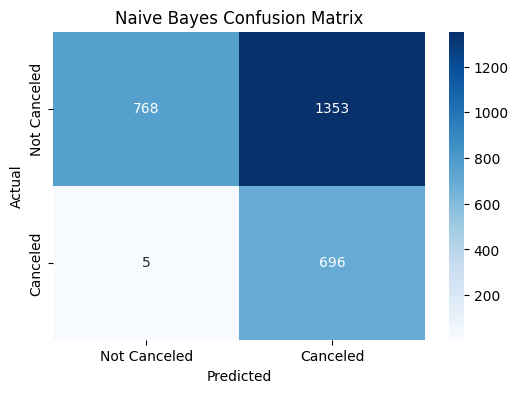

In [3]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import issparse

# Convert sparse matrices to dense arrays if needed
X_train_nb = X_train.toarray() if issparse(X_train) else X_train
X_test_nb = X_test.toarray() if issparse(X_test) else X_test

# Create and train Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_nb)

# Evaluate model performance
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print(f"Naive Bayes Accuracy: {nb_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

print("\nConfusion Matrix:")
nb_cm = confusion_matrix(y_test, y_pred_nb)
print(nb_cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(nb_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

### Reflection:
1. How well does the model perform?  And what metric is best used to judge the performance?
2. Where might this model be useful for the hotel (e.g. real-time alerts, operational decisions)?

### ✍️ Your Response: 🔧
1. The Naive Bayes model achieved an accuracy of 51.88%, which is relatively low. However, it achieved a recall of 99% for canceled bookings, correctly identifying 696 out of 701 cancellations. The main issue is that it incorrectly classified 1,353 bookings as canceled. I believe recall is the most important metric because the hotel wants to identify as many potential cancellations as possible. However, precision and F1-score should also be considered to avoid excessive false alarms.

2. This model could be useful for generating real time alerts when bookings are at risk of cancellation. Hotel management could use these predictions to send confirmation reminders, adjust staffing, and improve inventory and revenue planning. However, because the model produces a high number of false positives, I would recommend using it as an early warning system rather than relying on it to make final operational decisions.

## 3. Build a Support Vector Machine (SVM) Model

**Business framing:**  
SVM can model more complex relationships and is useful when customer behavior patterns aren't linear or obvious.

### Do the following:
- Scale the data using `StandardScaler` to bring large numbers into a smaller range (Note: use a scaled training set, but fit the scaler only on X_train).
- Train an SVM classifier (use `linear` kernel)
- Make predictions and evaluate with classification metrics

**NOTE:** With about 10K rows, this model may run very **slow**.  Be prepared to wait up to 10 minutes.   

SVM Accuracy: 87.85%

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      2121
           1       0.79      0.69      0.74       701

    accuracy                           0.88      2822
   macro avg       0.85      0.82      0.83      2822
weighted avg       0.87      0.88      0.88      2822


Confusion Matrix:
[[1994  127]
 [ 216  485]]


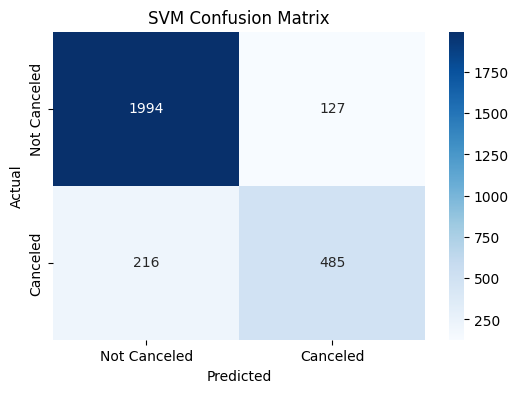

In [4]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Scale the training and testing data
scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and train the SVM model
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_scaled)

# Evaluate model performance
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"SVM Accuracy: {svm_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("\nConfusion Matrix:")
svm_cm = confusion_matrix(y_test, y_pred_svm)
print(svm_cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(svm_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

### Reflection:
1. How well does the model perform?  And what metric is best used to judge the performance?
2. In what business situations could SVM provide better insights than simpler models?

### ✍️ Your Response: 🔧
1. The SVM model performed significantly better than the Naive Bayes model, achieving an accuracy of 87.85%. It achieved a precision of 79%, a recall of 69%, and an F1-score of 74% for canceled bookings. It also reduced false positives from 1,353 to 127. I believe the F1-score is the best metric for evaluating this model because it balances precision and recall, helping the hotel identify potential cancellations while minimizing false alarms.

2. SVM could provide better insights when multiple factors influence customer behavior, such as lead time, previous cancellations, deposit type, and booking history. Hotels could use this model to improve staffing decisions, manage room availability, and forecast revenue more accurately. Compared to simpler models like Naive Bayes, SVM provides a better balance between identifying potential cancellations and correctly identifying bookings that will not be canceled.

## 4. Build a Neural Network Model

**Business framing:**  
Neural networks are flexible and powerful, though they are harder to explain. They may work well when subtle patterns exist in the data.

### Do the following:
- Build a MLPClassifier model using the neural_network package from sklearn
- Choose a simple architecture (e.g., 2 hidden layers)
- Use a true validation split from the training data, not the test set, for validation_data
- Evaluate accuracy and performance

**NOTE:** With about 10K rows, this model may run very **slow**.  Be prepared to wait up to 10 minutes.  

Neural Network Accuracy: 86.85%

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.91      2121
           1       0.76      0.69      0.72       701

    accuracy                           0.87      2822
   macro avg       0.83      0.81      0.82      2822
weighted avg       0.87      0.87      0.87      2822


Confusion Matrix:
[[1966  155]
 [ 216  485]]


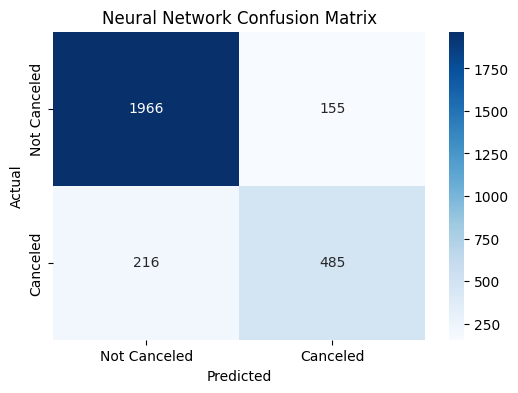

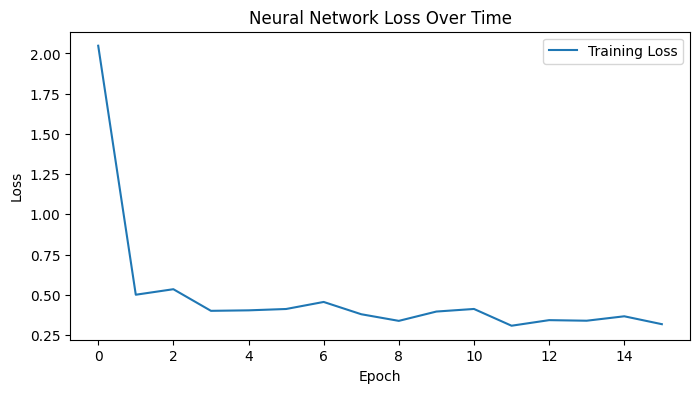

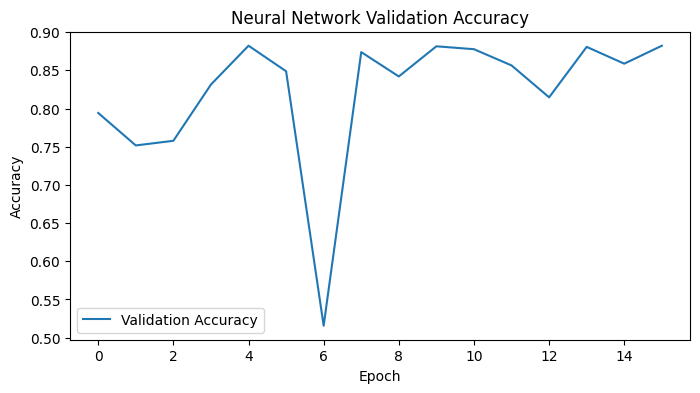

In [5]:
from sklearn.neural_network import MLPClassifier

# Create Neural Network model
nn_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    batch_size=32,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.2,
    random_state=42
)

# Train the model using scaled training data
nn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nn = nn_model.predict(X_test_scaled)

# Evaluate model performance
nn_accuracy = accuracy_score(y_test, y_pred_nn)

print(f"Neural Network Accuracy: {nn_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))

print("\nConfusion Matrix:")
nn_cm = confusion_matrix(y_test, y_pred_nn)
print(nn_cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(nn_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Neural Network Confusion Matrix')
plt.show()

# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(nn_model.loss_curve_, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Neural Network Loss Over Time')
plt.legend()
plt.show()

# Plot validation accuracy
plt.figure(figsize=(8, 4))
plt.plot(nn_model.validation_scores_, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Neural Network Validation Accuracy')
plt.legend()
plt.show()

### Reflection:
1. How does this model compare to the others?
2. Would the business be comfortable using a “black box” model like this? Why or why not?

### ✍️ Your Response: 🔧
1. The Neural Network achieved an accuracy of 86.85%, which was significantly better than Naive Bayes at 51.88% but slightly lower than SVM at 87.85%. Both the Neural Network and SVM correctly identified 485 canceled bookings, but the Neural Network produced more false positives. The training loss graph shows that the model improved over time, while validation accuracy fluctuated before reaching approximately 88%. Overall, SVM performed slightly better despite being a simpler model.

2. The business might be hesitant to use a black box model because it can be difficult to explain why certain bookings are predicted to be canceled. Hotel management may want to understand which factors influence predictions before making decisions about staffing, room availability, and revenue planning. Since SVM achieved slightly better performance and is easier to interpret, I believe management would be more comfortable using SVM in this situation.

## 5. Compare All Three Models

### Do the following:
- Print and compare the accuracy of Naïve Bayes, SVM, and Neural Network models
- Summarize which model performed best

Model Performance Comparison:
         Model  Accuracy
           SVM  0.878455
Neural Network  0.868533
   Naive Bayes  0.518781

Best Performing Model: SVM
Best Accuracy: 87.85%


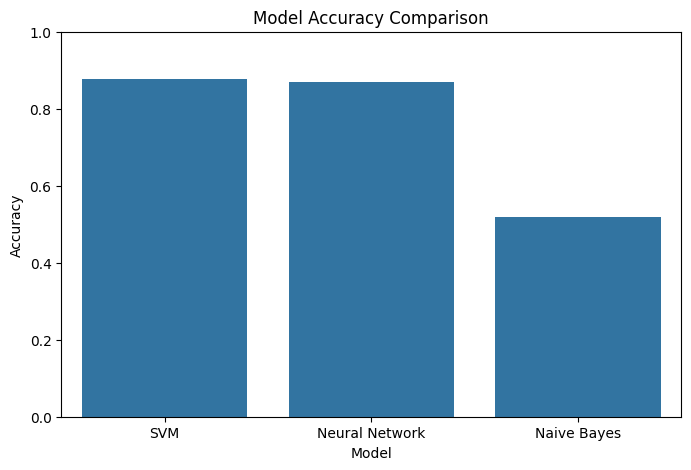

In [6]:
# Compare model accuracy
model_results = pd.DataFrame({
    'Model': ['Naive Bayes', 'SVM', 'Neural Network'],
    'Accuracy': [nb_accuracy, svm_accuracy, nn_accuracy]
})

# Sort models by accuracy
model_results = model_results.sort_values(
    by='Accuracy', ascending=False
)

print("Model Performance Comparison:")
print(model_results.to_string(index=False))

# Identify the best model
best_model = model_results.iloc[0]

print(f"\nBest Performing Model: {best_model['Model']}")
print(f"Best Accuracy: {best_model['Accuracy']:.2%}")

# Visualize model comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=model_results, x='Model', y='Accuracy')
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

### Reflection:
1. Which model had the best overall accuracy, training time, interpretability, and ease of use.
2. Would you recommend this model for deployment, and why?

### ✍️ Your Response: 🔧
1. The SVM model achieved the highest overall accuracy at 87.85%, followed by the Neural Network at 86.85% and Naive Bayes at 51.88%. Naive Bayes is generally the fastest to train and easiest to use and interpret, although we did not measure exact training times. The Neural Network was more complex and difficult to interpret without providing better accuracy than SVM. Overall, I believe SVM provides the best balance between accuracy, interpretability, and ease of use.

2. I would more likely recommend SVM for deployment because it achieved the highest accuracy and F1-score for canceled bookings while producing the fewest false positives. This could help hotel management improve staffing decisions, manage room availability, and forecast revenue more accurately. However, before fully deploying the model, I would recommend testing it on newer booking data and monitoring its performance to ensure it remains reliable over time.

## 6. Final Business Recommendation

### Reflection:
1. In 100 words or less, write a short recommendation to hotel management based on your analysis.

Possible info to include:
- Which model do you recommend implementing?
- What business problem does it help solve?
- Are there any risks or limitations?
- What additional data might improve the results in the future?

2. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. I recommend that hotel management implement the SVM model because it achieved the highest accuracy of 87.85% and provided the best balance between identifying cancellations and minimizing false alarms. This model could help improve staffing, room availability, and revenue forecasting. However, the model still missed some cancellations, so management should use it as a decision-making tool rather than relying on it entirely. Additional data, such as customer travel history, seasonal demand, and local events, could help improve future predictions.

2. This assignment relates to my customized learning outcomes of Data Visualization and Communication and Ethical Considerations in Analytics. As a Finance major, I want to develop the ability to communicate financial insights through clear visualizations while using data responsibly. Comparing these three models helped me understand that accuracy alone does not determine whether a model is reliable. This is important in finance because inaccurate predictions or misleading results could lead to poor financial decisions and negatively affect client trust.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_12_bayes_svm_neural.ipynb"